# M2 — Shared Preprocessing and Logistic Regression
6001CMD | Group 8 | Default of Credit Card Clients (UCI #350)

Objectives: audit data quality, demonstrate the shared preprocessing pipeline, establish a logistic regression baseline, tune using positive-class F1, and examine numerical scaling. The final test set is reserved for M3.

## 1. Environment setup

In [3]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "preprocessing.py").exists())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from src.preprocessing import load_data, split_data, build_pipeline, get_cv, RANDOM_STATE
from src.logistic_regression import run_baseline, run_tuning, run_preprocessing_experiment, save_lr_results
print(sys.version)
print("pandas:", pd.__version__, "scikit-learn:", sklearn.__version__)

3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
pandas: 3.1.1 scikit-learn: 1.9.1


## 2. Dataset loading and quality audit
The proposed cleaning policy retains records and original category codes, removes ID from predictors, and validates the input schema. Team confirmation of the policy is pending.

In [4]:
df = load_data()
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())
print("Duplicates excluding ID:", df.drop(columns="ID").duplicated().sum())
print("Duplicate predictors:", df.drop(columns=["ID", "default_next_month"]).duplicated().sum())
display(df["default_next_month"].value_counts().rename("count").to_frame().assign(proportion=lambda x: x["count"] / len(df)))
for col in ["EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]:
    print(col, sorted(df[col].unique()))

Shape: (30000, 25)
Missing values: 0
Duplicate IDs: 0
Duplicates excluding ID: 35
Duplicate predictors: 56


,count,proportion
default_next_month,,
0,23364,0.7788
1,6636,0.2212


EDUCATION [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
MARRIAGE [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
PAY_0 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_2 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_3 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_4 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_5 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_6 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np

## 3. Shared preprocessing and validation protocol
Numerical variables are standardised for LR; categorical variables, including repayment status codes, are one-hot encoded. The shared pipeline fits transformations inside each training fold. Tree models can disable numerical scaling. The stratified 80/20 split and shuffled three-fold stratified CV use seed 42.

In [5]:
X_train, X_test, y_train, y_test = split_data(df)
print("Training:", X_train.shape, "Held-out:", X_test.shape)
print("Index overlap:", len(X_train.index.intersection(X_test.index)))
assert "ID" not in X_train.columns and "default_next_month" not in X_train.columns
display(y_train.value_counts())
print(get_cv())
print(build_pipeline(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE), scale_numeric=True))

Training: (24000, 23) Held-out: (6000, 23)
Index overlap: 0


default_next_month
0    18691
1     5309
Name: count, dtype: int64

StratifiedKFold(n_splits=3, random_state=42, shuffle=True)
Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('numeric', StandardScaler(),
                                                  ['LIMIT_BAL', 'AGE',
                                                   'BILL_AMT1', 'BILL_AMT2',
                                                   'BILL_AMT3', 'BILL_AMT4',
                                                   'BILL_AMT5', 'BILL_AMT6',
                                                   'PAY_AMT1', 'PAY_AMT2',
                                                   'PAY_AMT3', 'PAY_AMT4',
                                                   'PAY_AMT5', 'PAY_AMT6']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['SEX', 'EDU

## 4. Logistic regression baseline
Default primary hyperparameters with max_iter=2000; evaluation uses training CV only.

In [6]:
baseline_results = run_baseline(X_train, y_train)


=== Logistic Regression Baseline ===
ACCURACY: 0.8210 (SD: 0.0013)
PRECISION: 0.6804 (SD: 0.0090)
RECALL: 0.3605 (SD: 0.0029)
F1: 0.4713 (SD: 0.0010)
ROC_AUC: 0.7685 (SD: 0.0078)

Elapsed time: 0.59 seconds


## 5. Hyperparameter tuning
GridSearchCV compares 20 parameter combinations across three folds. Selection uses positive-class F1 only.

In [7]:
search, tuning_elapsed = run_tuning(X_train, y_train)
print(search.best_params_)
print(search.best_score_)


=== Logistic Regression Tuning ===
Best Parameters: {'model__C': 0.1, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
Best CV F1: 0.5347
Standard Deviation: 0.0134
Elapsed time: 13.95 seconds
{'model__C': 0.1, 'model__class_weight': 'balanced', 'model__solver': 'lbfgs'}
0.5346859143908457


## 6. Preprocessing impact experiment
The existing experiment holds LR hyperparameters fixed at the observed optimum (C=0.1, balanced, lbfgs) and changes numerical scaling only. Non-convergence warnings are retained as evidence of the iteration-limit constraint. Running this section regenerates the CSV.

In [8]:
impact = run_preprocessing_experiment(X_train, y_train)
display(impact)


=== Preprocessing Impact Experiment ===

With Scaling
ACCURACY: 0.7747 (SD: 0.0094)
PRECISION: 0.4926 (SD: 0.0176)
RECALL: 0.5849 (SD: 0.0074)
F1: 0.5347 (SD: 0.0134)
ROC_AUC: 0.7691 (SD: 0.0073)
Elapsed time: 0.53 seconds


c:\ML-Group8-Project-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\ML-Group8-Project-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.h


Without Scaling
ACCURACY: 0.7723 (SD: 0.0045)
PRECISION: 0.4878 (SD: 0.0086)
RECALL: 0.5775 (SD: 0.0057)
F1: 0.5288 (SD: 0.0066)
ROC_AUC: 0.7634 (SD: 0.0044)
Elapsed time: 10.48 seconds

Saved: results/preprocessing_impact.csv


c:\ML-Group8-Project-main\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,experiment,scale_numeric,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std,elapsed_seconds
0,With Scaling,True,0.774667,0.009363,0.492573,0.017614,0.584857,0.007376,0.534686,0.013352,0.769068,0.007263,0.531731
1,Without Scaling,False,0.772333,0.004546,0.487779,0.008562,0.577511,0.005671,0.528836,0.006572,0.763408,0.004439,10.484371


## 7. Export and compare results
Running this section regenerates lr_cv.json. Times may differ across runs.


Saved: results/lr_cv.json


,Baseline,Tuned (scaled)
accuracy,0.8210,0.7747
precision,0.6804,0.4926
recall,0.3605,0.5849
f1,0.4713,0.5347
roc_auc,0.7685,0.7691


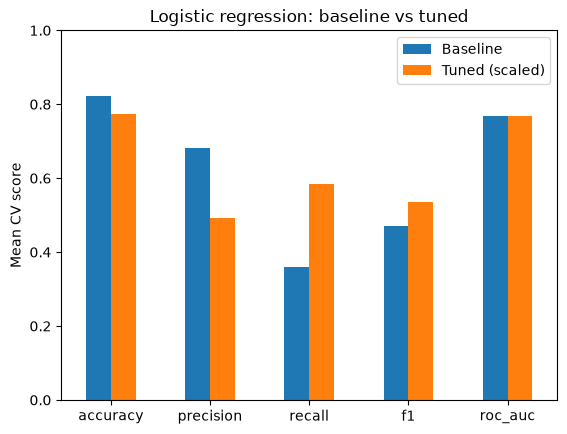

In [9]:
lr_results = save_lr_results(baseline_results, search, tuning_elapsed)
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]
scaled = impact.loc[impact["scale_numeric"] == True].iloc[0]
comparison = pd.DataFrame({"Baseline": [baseline_results[f"test_{m}"].mean() for m in metrics], "Tuned (scaled)": [scaled[f"{m}_mean"] for m in metrics]}, index=metrics)
display(comparison.round(4))
comparison.plot.bar(rot=0, ylim=(0,1), ylabel="Mean CV score", title="Logistic regression: baseline vs tuned");

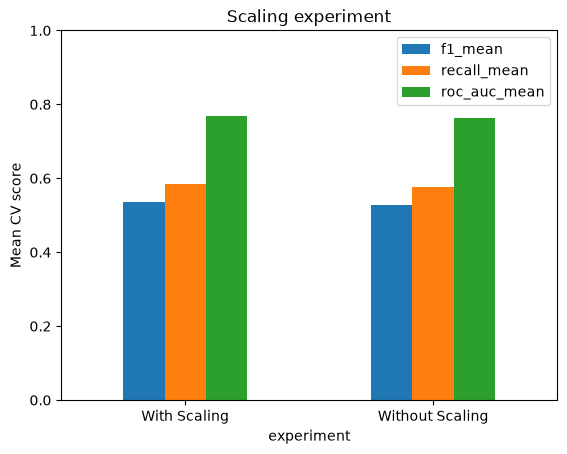

In [10]:
impact.set_index("experiment")[["f1_mean", "recall_mean", "roc_auc_mean"]].plot.bar(rot=0, ylim=(0,1), ylabel="Mean CV score", title="Scaling experiment");

## 8. Conclusion and limitations
In the recorded local run, tuning improved mean CV F1 from 0.4713 to 0.5347 and recall from 0.3605 to 0.5849, with lower accuracy and precision. Scaling yielded F1 0.5347 versus 0.5288 without scaling; all three unscaled folds reached the 2000-iteration limit, so their scores represent an incompletely converged model, not an optimised unscaled alternative. Runtime was 0.52 s with scaling and 9.35 s without in that run; runtime is environment-dependent. Duplicate predictor records and possible cross-split feature overlap remain limitations. The tuned CV score is a model-selection estimate, not independent test performance. Final test evaluation is reserved for M3. Team approval of cleaning policy and receiver-side integration testing remain to be confirmed. If a later run selects different parameters, update the fixed-parameter experiment and interpretation accordingly.